In [34]:
import pandas as pd
from sklearn.cluster import KMeans

value_system_df = pd.read_csv('ESS/Country/PVS/0/ESS_PVS.csv', sep=',', na_values=[''], quotechar='"')
value_system_df

,country,P__Self-Transcendence__Self-Transcendence,P__Self-Transcendence__Conservation,P__Self-Transcendence__Self-Enhancement,P__Self-Transcendence__Openness to Change,P__Conservation__Self-Transcendence,P__Conservation__Conservation,P__Conservation__Self-Enhancement,P__Conservation__Openness to Change,P__Self-Enhancement__Self-Transcendence,...,P__Openness to Change__Self-Enhancement,P__Openness to Change__Openness to Change,VA__Self-Transcendence__immigration,VA__Self-Transcendence__lgbt_freedom,VA__Conservation__immigration,VA__Conservation__lgbt_freedom,VA__Self-Enhancement__immigration,VA__Self-Enhancement__lgbt_freedom,VA__Openness to Change__immigration,VA__Openness to Change__lgbt_freedom
0,AT,0.5,0.792572,1.000000,0.927375,0.207428,0.5,0.707428,0.634803,0.000000,...,0.572625,0.5,0.045548,0.467084,0.001854,0.019013,-0.029124,-0.298661,-0.018278,-0.187436
1,BE,0.5,0.810897,1.000000,0.821273,0.189103,0.5,0.689103,0.510376,0.000000,...,0.678727,0.5,0.046784,0.525762,-0.004604,-0.051741,-0.035861,-0.403006,-0.006319,-0.071014
2,BG,0.5,0.560816,0.937123,1.000000,0.439184,0.5,0.876307,0.939184,0.062877,...,0.437123,0.5,-0.091643,0.003580,-0.069304,0.002707,0.068925,-0.002692,0.092022,-0.003595
3,CH,0.5,0.874166,1.000000,0.795380,0.125834,0.5,0.625834,0.421214,0.000000,...,0.704620,0.5,0.183185,0.493325,-0.051236,-0.137981,-0.130074,-0.350293,-0.001876,-0.005051
4,CY,0.5,0.642497,1.000000,0.883879,0.357503,0.5,0.857503,0.741382,0.000000,...,0.616121,0.5,-0.117191,0.121199,-0.052110,0.053892,0.111168,-0.114970,0.058133,-0.060122
5,CZ,0.5,0.588111,1.000000,0.855247,0.411889,0.5,0.911889,0.767136,0.000000,...,0.644753,0.5,-0.081264,0.210166,-0.050903,0.131647,0.091023,-0.235404,0.041145,-0.106409
6,DE,0.5,0.820831,1.000000,0.827467,0.179169,0.5,0.679169,0.506637,0.000000,...,0.672533,0.5,0.174323,0.498239,-0.020498,-0.058586,-0.129297,-0.369548,-0.024528,-0.070105
7,DK,0.5,0.841964,1.000000,0.797117,0.158036,0.5,0.658036,0.455153,0.000000,...,0.702883,0.5,0.072952,0.567407,-0.014652,-0.113959,-0.055138,-0.428848,-0.003163,-0.024601
8,EE,0.5,0.702408,1.000000,0.831935,0.297592,0.5,0.797592,0.629527,0.000000,...,0.668065,0.5,-0.019766,0.130960,-0.004294,0.028451,0.018454,-0.122264,0.005607,-0.037148
9,ES,0.5,0.682358,1.000000,0.814293,0.317642,0.5,0.817642,0.631935,0.000000,...,0.685707,0.5,0.120797,0.455324,0.032388,0.122080,-0.121609,-0.458384,-0.031576,-0.119021


## Notes

- "Immigration" means "Immigration bad or good for country's economy", where a higher value means **good**.
- "lgbt_freedom" means "Gay men and lesbians should be free to live life as they wish", where a higher value means **yes**

- If no country is specified, plots are over **all** countries

## Step 1: Understand the relationship of action judgements
- An action judgement states: If the action is taken, then to what extent will my value be promoted or demoted? (In the opinion of the agent)

### Key Conclusions
-

In [35]:
# Find all columns that start with "P__"
pref_cols = pd.DataFrame(value_system_df.filter(regex="^P__"))
# Remove all cols that have the same two values (P__Universalism__Universalism, P__Benevolence__Benevolence, etc.)
for col in pref_cols.columns:
    col_split = col.split("__")
    if len(col_split) == 3 and col_split[1] == col_split[2]:
        pref_cols = pref_cols.drop(col, axis=1)
    else:
        # Not dropped, so drop the symmetrical col (P__A__B == P__B__A)
        symmetrical_col = "P__"+ col_split[2] + "__" + col_split[1]
        if col in pref_cols.columns:
            pref_cols = pref_cols.drop(columns=[symmetrical_col])
print("len of pref_cols: ", len(pref_cols.keys()))

len of pref_cols:  6


In [36]:
stds = pref_cols.std()
stds = stds.sort_values(ascending=True)
print("Standard Deviations for each comparison: \n", stds)

Standard Deviations for each comparison: 
 P__Self-Transcendence__Self-Enhancement      0.015919
P__Self-Transcendence__Openness to Change    0.070961
P__Self-Enhancement__Openness to Change      0.081262
P__Conservation__Self-Enhancement            0.104948
P__Self-Transcendence__Conservation          0.112787
P__Conservation__Openness to Change          0.172282
dtype: float64


Low means:  P__Self-Enhancement__Openness to Change      0.367801
P__Conservation__Openness to Change          0.648956
P__Self-Transcendence__Conservation          0.713641
P__Conservation__Self-Enhancement            0.781155
P__Self-Transcendence__Openness to Change    0.862597
P__Self-Transcendence__Self-Enhancement      0.994797
dtype: float64
filtered low means:  P__Self-Enhancement__Openness to Change    0.367801
dtype: float64
6


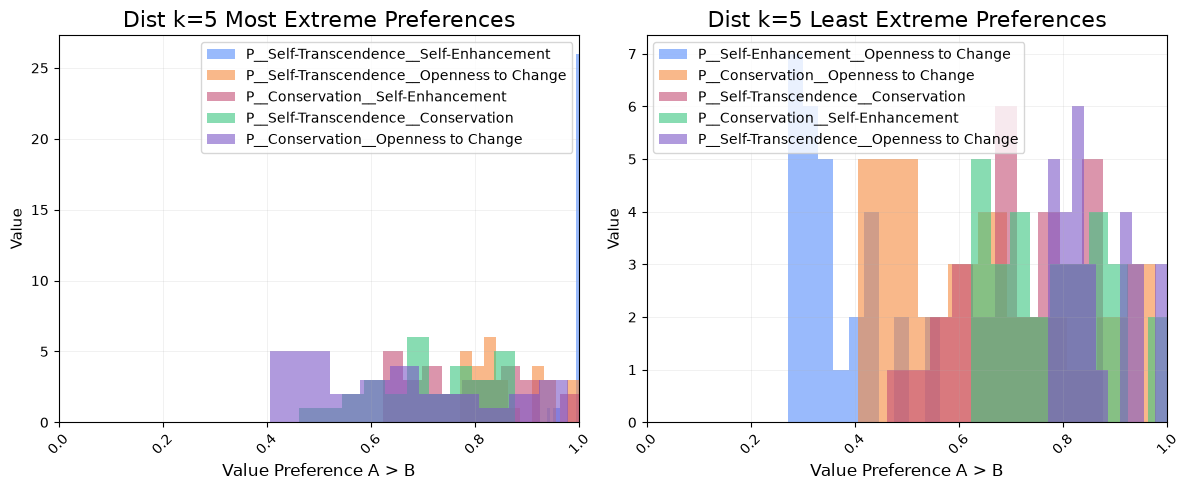

In [37]:
# There are 16 pairwise comparisons, look at top 5 strongest for each (most irrelevant vs strongest)
import matplotlib.pyplot as plt
import copy
k = 5
# Find cols that have a mean closest to 0 or 1, find the absolute difference to either 0 or 1 (depending on which side of 0.5 they're on), and then rank the distances
high_means = pref_cols.mean(axis=0).sort_values(ascending=False)
low_means = pref_cols.mean(axis=0).sort_values(ascending=True)
print("Low means: ", low_means)
# Drop all rows where value is less than 0.5
high_means = high_means[high_means >= 0.5]
low_means = low_means[low_means < 0.5]
print("filtered low means: ", low_means)
# Normalise: Find diff, so the strength will be equal
low_means = 1 - low_means

# Concat
means = pd.concat([high_means, low_means])
means = means.sort_values(ascending=False)
print(len(means))
means_keys_high = copy.copy(means.keys().tolist()[:k])
means = means.sort_values(ascending=True)
means_keys_low = means.keys().tolist()[:k]
#print("Low keys: ", means_keys_low)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1]})

for col in means_keys_high:
    pref_cols.hist(col, bins=10, alpha=0.6, label=col, ax=axes[0])
axes[0].set_title(f"Dist k={k} Most Extreme Preferences", fontsize=16)
axes[0].set_xlabel('Value Preference A > B', fontsize=12)
axes[0].set_ylabel('Frequency Amongst Agents', fontsize=12)
axes[0].legend(fontsize=10)
axes[0].set_ylabel("Value", fontsize=11)
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(alpha=0.25)
axes[0].set_xlim(0, 1)

for col in means_keys_low:
    pref_cols.hist(col, bins=10, alpha=0.6, label=col, ax=axes[1])
axes[1].set_title(f"Dist k={k} Least Extreme Preferences", fontsize=16)
axes[1].set_xlabel('Value Preference A > B', fontsize=12)
axes[1].set_ylabel('Frequency Amongst Agents', fontsize=12)
axes[1].legend(fontsize=10)
axes[1].set_ylabel("Value", fontsize=11)
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(alpha=0.25)
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()


mean of means is:  0.7722242901405342


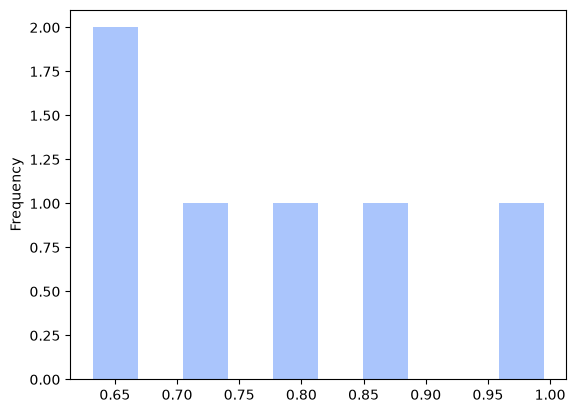

In [38]:
# Find cols that have a mean closest to 0 or 1, find the absolute difference to either 0 or 1 (depending on which side of 0.5 they're on), and then rank the distances
high_means = pref_cols.mean(axis=0).sort_values(ascending=False)
low_means = pref_cols.mean(axis=0).sort_values(ascending=True)

# Drop all rows where the value is less than/above 0.5, then transform
high_means = high_means[high_means >= 0.5]
low_means = low_means[low_means < 0.5]
low_means = 1-low_means
means = pd.concat([high_means, low_means])

print("mean of means is: ", sum(means)/len(means))
## plot hist of means
ax = means.plot.hist(bins=10, alpha=0.5)

### Notes on Value Preferences
- What happens to the performance of value aggregators when we remove the "noise" of indifferent value preferences?
- Are the extreme value preferences reflected in our actions? Are more extreme opinions on the actions shared by agents with more extreme value preferences?

VA__Self-Transcendence__immigration    0.035717
VA__Openness to Change__immigration    0.010292
VA__Conservation__immigration         -0.019780
VA__Self-Enhancement__immigration     -0.026230
dtype: float64


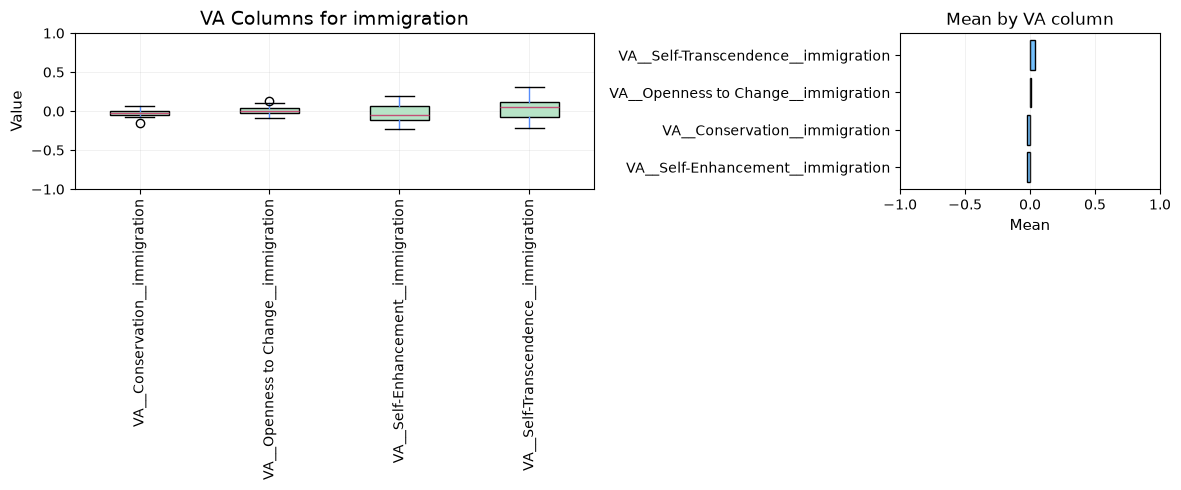

In [39]:
import re
import matplotlib.pyplot as plt

def _va_cols_for_topic(df, topic: str):
    # Get all VA columns for a given topic
    pattern = re.compile(rf"^VA__.*__{re.escape(topic)}$", flags=re.IGNORECASE)
    return [c for c in df.columns if pattern.match(c)]

def plot_va_topic(df, topic: str, figsize=(12, 5)):
    # Plot VA boxplot and mean by VA column for a given topic
    cols = _va_cols_for_topic(df, topic)
    if not cols:
        raise ValueError(f"No VA columns found for topic '{topic}'. Expected columns like 'VA__<Value>__{topic}'.")
    cols = sorted(cols)

    fig, axes = plt.subplots(1, 2, figsize=figsize, gridspec_kw={"width_ratios": [2, 1]})

    df[cols].boxplot(ax=axes[0], patch_artist=True, boxprops=dict(facecolor="#b7e4c7"))
    axes[0].set_title(f"VA Columns for {topic}", fontsize=14)
    axes[0].set_ylabel("Value", fontsize=11)
    axes[0].tick_params(axis="x", rotation=90)
    axes[0].set_ylim(-1, 1)
    axes[0].grid(alpha=0.25)


    means = df[cols].mean(numeric_only=True).sort_values(ascending=False)
    print(means)
    axes[1].barh(means.index, means.values, color="#74c0fc", edgecolor="black")
    axes[1].set_title("Mean by VA column", fontsize=12)
    axes[1].set_xlabel("Mean", fontsize=11)
    axes[1].invert_yaxis()
    axes[1].set_xlim(-1, 1)
    axes[1].grid(axis="x", alpha=0.25)

    plt.tight_layout()
    plt.show()

    # Save cols to a .csv
    cols_df = pd.DataFrame(df[cols])
    cols_df.to_csv(f"VA_{topic}.csv", index=False)

plot_va_topic(value_system_df, "immigration")

### Notes: Immigration is good for the economony Action
- Medium-Strength (+/- 0.5) matching Schwartz Values
    - Self-Direction, Stimulation, Power, Benevolence, Universalism

VA__Self-Transcendence__lgbt_freedom    0.307624
VA__Conservation__lgbt_freedom         -0.004631
VA__Openness to Change__lgbt_freedom   -0.053355
VA__Self-Enhancement__lgbt_freedom     -0.249639
dtype: float64


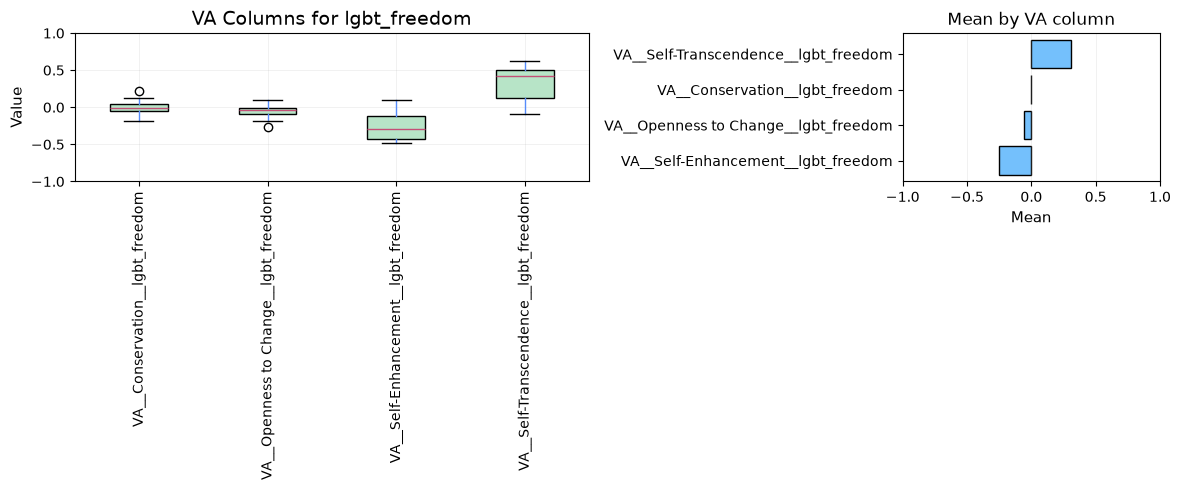

In [40]:
plot_va_topic(value_system_df, "lgbt_freedom")

### Notes: LGBT Rights Action
- Low-Strength correlation between values and actions, with a few agents having stronger correlations.
- No overall large trend.

### Notes: LGBT Adoption Action
- Low-Strength correlation with no extreme positions within the entire group.

### K-Means clustering/PCA analysis to find clusters of agents with similar action judgements
- Here we are looking to find distinct clusters. An ideal scenario would be i) one large cluster, with a small opposing cluster ii) two strongly opposing clusters of similar size. iii) No clear clusters.

In [41]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def _va_cols_for_action(df: pd.DataFrame, action: str):
    suffix = f"__{action}"
    return [c for c in df.columns if c.startswith("VA__") and c.endswith(suffix)]

def PCA_per_action(df, actions=("immigration", "lgbt_freedom")):
    for action in actions:
        cols = sorted(_va_cols_for_action(df, action))
        scaler = StandardScaler()
        # take col data, and scale between 0-1, std 1, for PCA
        X = df[cols].to_numpy(dtype=float)
        X = scaler.fit_transform(X)
        pca_output = PCA(n_components=2).fit_transform(X)

        plt.figure(figsize=(6.5, 5.2))
        plt.scatter(pca_output[:, 0], pca_output[:, 1], s=55, alpha=0.85, edgecolor="white", linewidth=0.5, label=action)
        plt.title(f"PCA view of {action} action judgements")
        plt.xlabel("PC1")
        plt.ylabel("PC2")
        plt.xlim(-4, 4)
        plt.ylim(-4, 4)
        plt.grid(alpha=0.25)
        plt.legend(frameon=True)

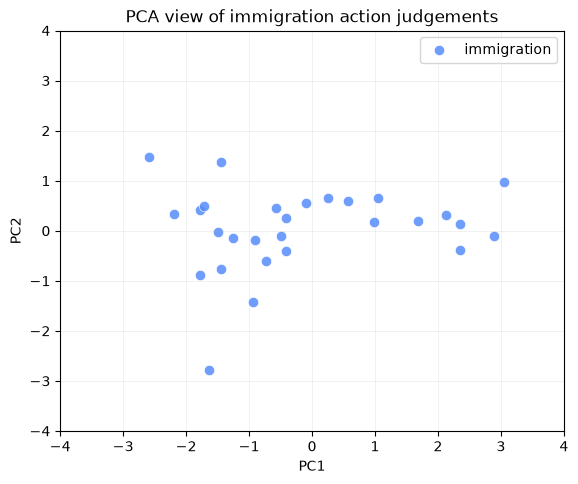

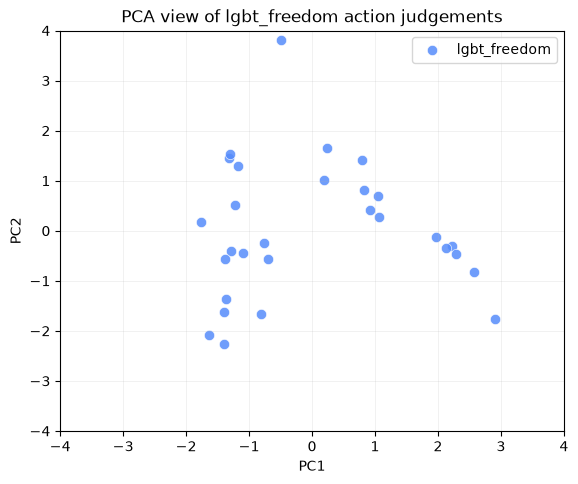

In [42]:
PCA_per_action(value_system_df)